# Listas · Autómatas celulares

Matrices y listas que evolucionan con reglas locales: el juego de la vida de Conway y autómatas unidimensionales.

## 1. Juego de la vida

Una célula viva sobrevive con 2 o 3 vecinas vivas; una muerta nace con exactamente 3. Implementarlo y comprobar si funciona contar vecinas sumando las 9 casillas y restando la propia (sí, si se usa `tablero[y+i][x+j]` y no `tablero[y+i, x+j]`).

In [1]:
def vecinas(tablero, y, x):
    filas, columnas = len(tablero), len(tablero[0])
    n = -tablero[y][x]
    for i in (-1, 0, 1):
        for j in (-1, 0, 1):
            if 0 <= y + i < filas and 0 <= x + j < columnas:
                n += tablero[y + i][x + j]
    return n

def paso(tablero, nacer=(3,), sobrevivir=(2, 3), vecinas=vecinas):
    return [[int(vecinas(tablero, y, x) in (sobrevivir if tablero[y][x] else nacer)) for x in range(len(tablero[0]))]
            for y in range(len(tablero))]

def muestra(tablero):
    print("\n".join("".join("#" if c else "." for c in fila) for fila in tablero), end="\n\n")

planeador = [[0] * 8 for _ in range(6)]
for y, x in ((0, 1), (1, 2), (2, 0), (2, 1), (2, 2)):
    planeador[y][x] = 1
t = planeador
for _ in range(3):
    muestra(t)
    t = paso(t)

.#......
..#.....
###.....
........
........
........

........
#.#.....
.##.....
.#......
........
........

........
..#.....
#.#.....
.##.....
........
........



## 2. Juego de la vida parametrizado

Pedir cuántas vecinas vivas hacen nacer y sobrevivir a una célula, y mostrar la evolución.

In [2]:
nacer = tuple(int(v) for v in input("Vecinas para nacer: ").split())
sobrevivir = tuple(int(v) for v in input("Vecinas para sobrevivir: ").split())
pasos = int(input("Pasos: "))
t = planeador
for _ in range(pasos):
    t = paso(t, nacer, sobrevivir)
muestra(t)

Vecinas para nacer: 3 6
Vecinas para sobrevivir: 2 3
Pasos: 2
........
..#.....
#.#.....
.##.....
........
........



## 3. Juego de la vida toroidal

En el tablero toroidal los bordes se tocan: las vecinas se calculan con índices módulo filas y columnas. Mostrarlo gráficamente.

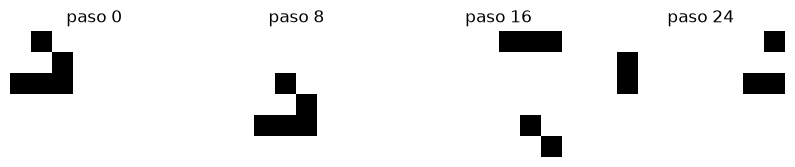

In [3]:
import matplotlib.pyplot as plt

def vecinas_toroidal(tablero, y, x):
    m, n = len(tablero), len(tablero[0])
    return sum(tablero[(y + i) % m][(x + j) % n] for i in (-1, 0, 1) for j in (-1, 0, 1)) - tablero[y][x]

t = planeador
fig, ejes = plt.subplots(1, 4, figsize=(10, 2.5))
for k, eje in enumerate(ejes):
    eje.imshow(t, cmap="binary")
    eje.set_title(f"paso {k * 8}")
    eje.axis("off")
    for _ in range(8):
        t = paso(t, vecinas=vecinas_toroidal)
plt.show()

## 4. Autómata celular unidimensional

Cada celda depende de sí misma y de sus vecinas izquierda y derecha. Leer las 8 reglas (`000 0 001 1 ...`) y el número de pulsos, y mostrar la evolución desde una sola celda viva en el centro con `*` y `.`.

In [4]:
partes = input("Reglas: ").split()
reglas = dict(zip(partes[::2], partes[1::2]))
pulsos = int(input("Pulsos: "))

def evoluciona(reglas, pulsos, ancho=21):
    celdas = ["0"] * ancho
    celdas[ancho // 2] = "1"
    historia = [celdas]
    for _ in range(pulsos - 1):
        extendida = ["0"] + celdas + ["0"]
        celdas = [reglas["".join(extendida[i - 1:i + 2])] for i in range(1, ancho + 1)]
        historia.append(celdas)
    return historia

for i, fila in enumerate(evoluciona(reglas, pulsos)):
    print(f"Pulso {i} : " + "".join("*" if c == "1" else "." for c in fila))

Reglas: 000 0 001 1 010 1 011 0 100 1 101 1 110 0 111 0
Pulsos: 7
Pulso 0 : ..........*..........
Pulso 1 : .........***.........
Pulso 2 : ........*...*........
Pulso 3 : .......***.***.......
Pulso 4 : ......*...*...*......
Pulso 5 : .....***.***.***.....
Pulso 6 : ....*...*...*...*....


## 5. Representación gráfica del autómata

Mostrar cada pulso como una fila de una imagen. Con estas reglas aparece el triángulo de Sierpinski.

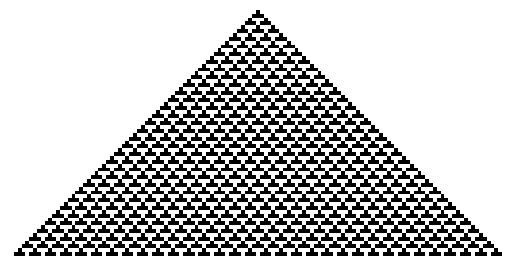

In [5]:
plt.imshow([[int(c) for c in fila] for fila in evoluciona(reglas, 64, ancho=129)], cmap="binary")
plt.axis("off")
plt.show()